# Vẽ hiện tượng chưa khớp, vừa khớp, quá khớp (mục 2.2.4): hồi quy đa thức bậc 1, 4, 12 trên 15 điểm

Đã lưu hình: underfitting_overfitting.png


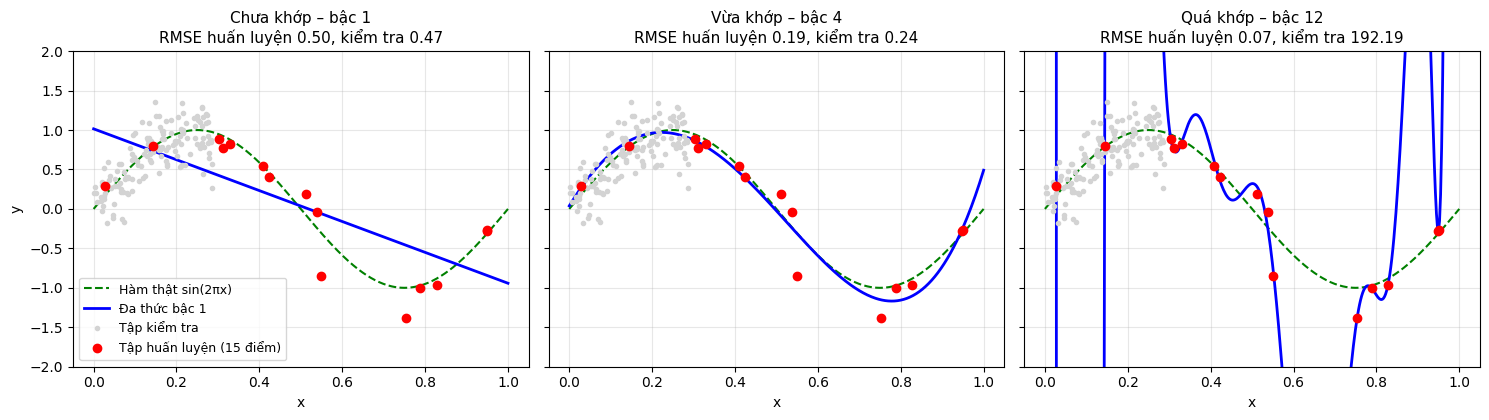

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression

OUTPUT = Path('underfitting_overfitting.png')   # ảnh lưu cạnh notebook

def make_data(n, rng):
    """Sinh n điểm (x, y) với y = sin(2πx) + nhiễu, x trong [0, 1)."""
    x = np.sort(rng.uniform(0, 1, n))
    y = np.sin(2 * np.pi * x) + rng.normal(0, 0.2, n)
    return x.reshape(-1, 1), y

def poly_model(degree):
    """Hồi quy đa thức bậc degree (chuẩn hóa trước khi lũy thừa để nghiệm ổn định)."""
    return make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                         StandardScaler(), LinearRegression())

def rmse(model, X, y):
    """Căn bậc hai của sai số bình phương trung bình."""
    return np.sqrt(np.mean((model.predict(X) - y) ** 2))

rng = np.random.default_rng(1)              # cùng dữ liệu với notebook 06, 07
X_train, y_train = make_data(15, rng)       # tập huấn luyện
X_val, y_val = make_data(15, rng)           # tập xác thực (không dùng ở hình này)
X_test, y_test = make_data(500, rng)        # tập kiểm tra

x_plot = np.linspace(0, 1, 400).reshape(-1, 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, degree, title in zip(axes, [1, 4, 12], ['Chưa khớp', 'Vừa khớp', 'Quá khớp']):
    model = poly_model(degree).fit(X_train, y_train)
    ax.plot(x_plot, np.sin(2 * np.pi * x_plot), 'g--', lw=1.5, label='Hàm thật sin(2πx)')
    ax.plot(x_plot, model.predict(x_plot), 'b', lw=2, label=f'Đa thức bậc {degree}')
    ax.plot(X_test[:150], y_test[:150], '.', color='lightgray', label='Tập kiểm tra')
    ax.plot(X_train, y_train, 'ro', label='Tập huấn luyện (15 điểm)')
    ax.set_ylim(-2, 2)
    ax.set_xlabel('x')
    ax.set_title(f'{title} – bậc {degree}\nRMSE huấn luyện {rmse(model, X_train, y_train):.2f}, '
                 f'kiểm tra {rmse(model, X_test, y_test):.2f}', fontsize=11)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('y')
axes[0].legend(loc='lower left', fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT, dpi=150)
print('Đã lưu hình:', OUTPUT)